In [9]:
import pandas as pd

df=pd.read_csv("machine_remaining_useful_life.csv")
target="Remaining_Useful_Life_Hours"
df=df.drop_duplicates()
df=df.drop(columns=["Record_ID","id"],errors="ignore")
df

,Machine_Type,Shift,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,Remaining_Useful_Life_Hours
0,Type_C,Night,150.000000,67.815878,110.455979,90.903460,39.792372,264.618559
1,Type_A,Night,47.959694,140.000000,96.412504,94.075167,20.907232,343.707742
2,Type_C,Night,48.139435,50.305721,80.653516,80.918710,29.061708,346.289817
3,Type_C,Night,60.427652,55.793961,104.004805,94.162342,35.811543,268.553914
4,Type_A,Morning,55.059911,53.637579,103.441049,89.892950,29.423397,283.635936
...,...,...,...,...,...,...,...,...
995,Type_B,Morning,45.291710,47.493722,96.102289,93.310712,27.014817,327.560741
996,Type_B,Night,61.502960,59.444488,123.750668,113.161861,33.524736,257.303824
997,Type_C,Evening,52.798427,50.345172,78.279049,79.073056,36.435461,278.038353
998,Type_C,Night,35.226720,39.029742,94.203172,81.116722,29.773626,316.652233


In [10]:
print(df.head())
print(df.shape)
print(df.describe())

  Machine_Type    Shift    Sensor_1    Sensor_2    Sensor_3   Sensor_4  \
0       Type_C    Night  150.000000   67.815878  110.455979  90.903460   
1       Type_A    Night   47.959694  140.000000   96.412504  94.075167   
2       Type_C    Night   48.139435   50.305721   80.653516  80.918710   
3       Type_C    Night   60.427652   55.793961  104.004805  94.162342   
4       Type_A  Morning   55.059911   53.637579  103.441049  89.892950   

    Sensor_5  Remaining_Useful_Life_Hours  
0  39.792372                   264.618559  
1  20.907232                   343.707742  
2  29.061708                   346.289817  
3  35.811543                   268.553914  
4  29.423397                   283.635936  
(1000, 8)
         Sensor_1     Sensor_2    Sensor_3     Sensor_4     Sensor_5  \
count  970.000000  1000.000000  970.000000  1000.000000  1000.000000   
mean    50.370813    50.422399   99.536537    89.576571    30.198832   
std     10.442840     8.944902   14.984790    11.510094     5.041

In [11]:
print(df.isnull().sum())

Machine_Type                   30
Shift                           0
Sensor_1                       30
Sensor_2                        0
Sensor_3                       30
Sensor_4                        0
Sensor_5                        0
Remaining_Useful_Life_Hours     0
dtype: int64


<Axes: >

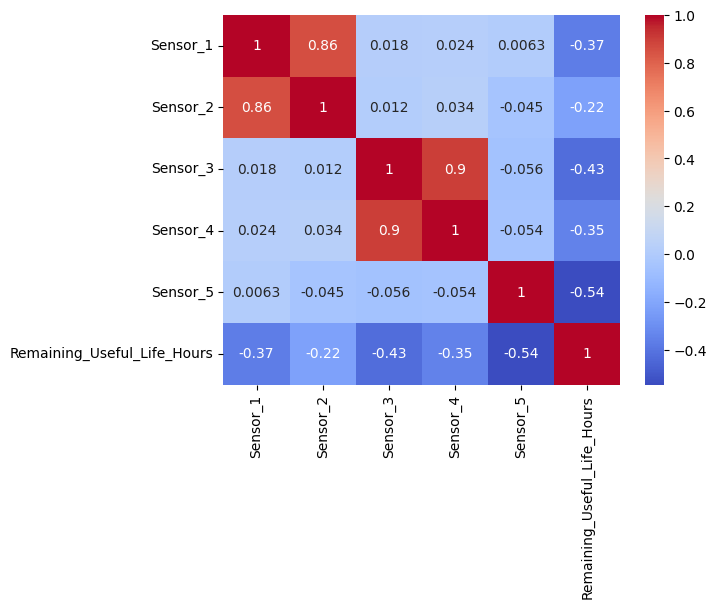

In [12]:
import seaborn as sns
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

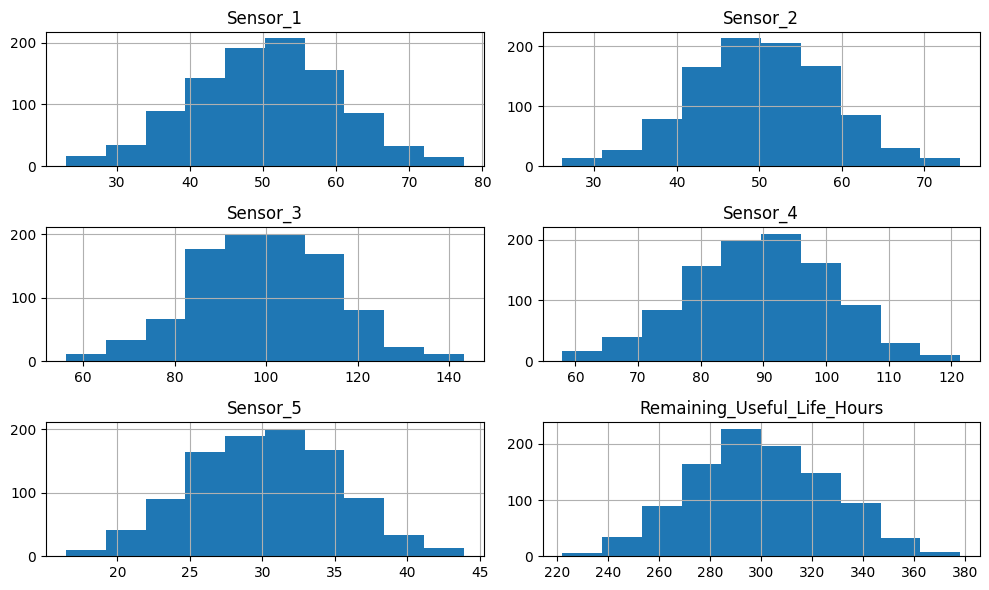

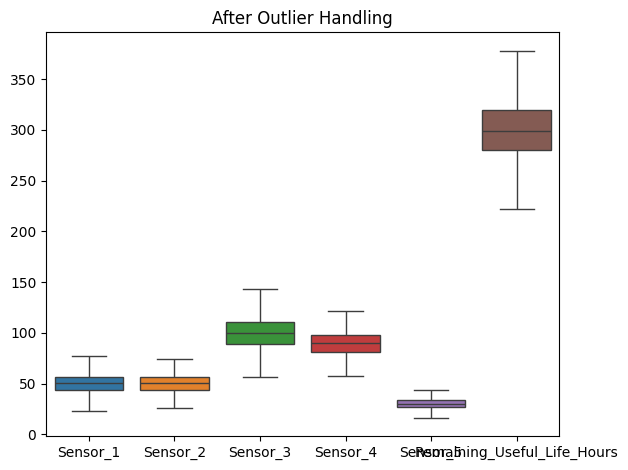

In [31]:
#HISTOGRAM
import matplotlib.pyplot as plt
df.hist(figsize=(10,6))
plt.tight_layout()
plt.show()

##BOX PLOT
sns.boxplot(data=df)
plt.title("After Outlier Handling")
plt.tight_layout()
plt.show()

In [23]:

import numpy as np
num_cols=df.select_dtypes(include=np.number).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR

    upper = Q3 + 1.5 * IQR

    df[col]=df[col].clip(lower,upper)


In [ ]:
##pipe line
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR
from sklearn.model_selection import KFold,StratifiedKFold


X=df.drop(columns=target)
y=df[target]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([("num", num_pipe, num_cols),("cat", cat_pipe, cat_cols)])

pipe1 = Pipeline([("preprocessor", preprocessor),("model",SVR())])

pipe2=Pipeline([("preprocessor", preprocessor),("pca", PCA()),("model",SVR())])

params={"model__C":[0.1,1,10],
        "model__gamma":["scale","auto"],
        "model__kernel":["rbf","linear"]}

cv=KFold(n_splits=5, shuffle=True, random_state=42)



In [42]:
from sklearn.model_selection import GridSearchCV
grid1=GridSearchCV(pipe1, params, cv=cv, n_jobs=-1,scoring="neg_root_mean_squared_error")
grid2=GridSearchCV(pipe2, params, cv=cv, n_jobs=-1,scoring="neg_root_mean_squared_error")

grid1.fit(X_train,y_train)
grid2.fit(X_train,y_train)

print("Without PCA best parameters :", grid1.best_params_)
print("Without PCA best score :", -grid1.best_score_)

print("With PCA best parameters :", grid2.best_params_)
print("With PCA best score :", -grid2.best_score_)


Without PCA best parameters : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Without PCA best score : 14.812268110510777
With PCA best parameters : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
With PCA best score : 14.81225566596278


In [44]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

for name, model in [("Without PCA", grid1.best_estimator_),
                    ("With PCA", grid2.best_estimator_)]:

    pred = model.predict(X_test)

    print("\n", name)
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("MAE:", mean_absolute_error(y_test, pred))
    print("R2:", r2_score(y_test, pred))




 Without PCA
RMSE: 19.574442727339264
MAE: 14.69353541232697
R2: 0.5093960969824884

 With PCA
RMSE: 19.574505328140756
MAE: 14.693524814705087
R2: 0.5093929589880043


In [47]:
from sklearn.model_selection import cross_val_score

scores1 = cross_val_score(grid1.best_estimator_, X_train, y_train, cv=cv)
scores2 = cross_val_score(grid2.best_estimator_, X_train, y_train, cv=cv)

print("Without PCA CV Score:", scores1.mean())
print("With PCA CV Score:", scores2.mean())

difference = scores1-scores2
print(difference)

Without PCA CV Score: 0.6880548203990366
With PCA CV Score: 0.6880553440594465
[-3.14225501e-07  3.77168897e-07 -8.68143013e-08 -2.06615989e-06
 -5.28271256e-07]


In [46]:
from scipy.stats import ttest_rel
paired_stat, paired_p = ttest_rel(scores1, scores2)
if paired_p < 0.05:
    print("Paired t-test: Significant difference")
else:
    print("Paired t-test: No significant difference")


Paired t-test: No significant difference
